# Hybrid LCA of solar PV supply chains in an extended EXIOBASE

This notebook builds a hybrid multi-regional input–output (MRIO) model that embeds an
**explicit photovoltaic (PV) supply chain** into a hybrid-units EXIOBASE supply-and-use
table, and uses it to compute the **carbon footprint, price, production, value added and
employment** of solar electricity across world regions and policy scenarios.

The pipeline runs from raw database to figures:

1. **Base database** — parse and aggregate the hybrid-units SUT
2. **PV supply chain** — add the explicit PV activities and apply the PV physics
3. **Scenarios** — domestic, real trade, reshoring policy, and a projected 2030 grid
4. **Indicators** — footprint / price / production for one model run
5. **Global sensitivity analysis** — sweep the model levers and export every result
6. **Figures** — generate the publication figures from the exported tables
7. **Save** — write the extended database for sharing (optional)

All model-specific logic lives in the `pv_hlca` package under `src/`. The cells favour the
**MARIO API** directly and call the package only for the PV-specific physics and the
indicator/figure helpers, so the pipeline stays readable and adaptable.

## Setup

Import the libraries and load the configuration (paths, parameters, mappings).

In [2]:
import sys
from pathlib import Path

# make the local `pv_hlca` package importable whether the notebook is run from the
# repo root or from the notebooks/ folder
REPO = Path.cwd()
REPO = REPO.parent if REPO.name == "notebooks" else REPO
sys.path.insert(0, str(REPO / "src"))

import mario
import pandas as pd
import matplotlib.pyplot as plt

from pv_hlca import io, hybridize, scenarios, indicators, export, figures
from pv_hlca.params import Params, grid

cfg = io.load_config()
mario.set_log_verbosity("critical")

## 1. Base database

The base hybrid-units supply-and-use table (EXIOBASE extended with hydrogen and green
steel) is archived on **Zenodo, record 18744457**. Download its SUT parquet files into
`inputs/db_from_zenodo/` (git-ignored; see `config/paths.yaml`). The cell below checks the
database is present, then parses and aggregates it (regions 48→22, value-added 8→4,
satellite 363→25).

In [ ]:
# --- check the base database is present (download from Zenodo otherwise) ---
base = cfg["base_db"]["_path"]
if not any(base.rglob("*.parquet")):
    raise FileNotFoundError(
        f"Base database not found in {base}.\n"
        f"Download the SUT parquet files from {cfg['base_db']['zenodo']} "
        f"into that folder, then re-run this cell."
    )

# --- parse + aggregate  (MARIO API) ---
db = mario.parse_from_parquet(
    path=str(base),
    table=cfg["base_db"]["table"],
    mode=cfg["base_db"]["mode"],
)
db.aggregate(io=str(cfg["data"]["aggregation"]), ignore_nan=True, zero_output_epsilon=None)

db

## 2. Photovoltaic supply chain

Insert the explicit PV activities and commodities (with their life-cycle inventories) using
MARIO's `add_sectors`, then apply the PV physics:

- **capacity factor** — regional solar yield scaling (`OWID` or `RN` source)
- **module efficiency** — area-proportional module inputs (reference 19.5 %)
- **degradation rate** — lifetime-yield correction (reference 0 = constant output)
- **upstream-electricity LCI** — IEA PVPS (reference) or NREL inventory
- **value added** — IRENA-based CAPEX / labour for the Solar Power Plant

Finally the legacy aggregate `Solar` activity is neutralised so that the explicit
`Solar Power Plant` becomes the sole producer of solar electricity.

The chosen lever values are collected in a `Params` object; the defaults define the central
reference case (the full sweep is in section 5). **Change any lever by editing the
`Params(...)` call** below.

In [ ]:
params = Params()    # central case: OWID capacity factors, WEO_STEPS 2030 grid, 19.5%
                     # efficiency, no degradation, IEA PVPS upstream LCI, no forced reshoring
# change levers here, e.g. Params(capacity_factor="RN", module_efficiency=0.24, lci_variant="NREL")
print(params)

# 2a. add the PV activities / commodities and their inventories  (MARIO API)
db.read_add_sectors_excel(path=str(cfg["data"]["add_sectors"]), read_inventories=True)
db.add_sectors()

# 2b. apply the PV physics and neutralise the legacy 'Solar'  (model-specific helpers)
hybridize.apply_solar_shock(db, cfg, variant=params.capacity_factor,
                            degradation_rate=params.degradation_rate)
hybridize.apply_module_efficiency(db, cfg, params.module_efficiency)
hybridize.apply_lci_variant(db, cfg, params.lci_variant)   # upstream-electricity inventory (IEA/NREL)
hybridize.remove_old_solar(db, cfg)

db

## 3. Scenarios

Build the scenario set on the hybridised database. Each scenario is a MARIO scenario cloned
from `baseline` and shocked on the use block:

| scenario | meaning |
|---|---|
| `domestic` | autarkic PV (each region supplies its own PV chain) |
| `baseline` | real, China-dominated import structure |
| `NZIA` | EU reshoring policy (Net-Zero Industry Act targets) |
| `baseline_2030` | real trade with the projected 2030 electricity mix |

The 2030 grid and the trade structure are data-driven (`electricity_mix` source and the
import-structure table); `upstream_reshoring` optionally forces the EU domestic share of the
upstream PV commodities.

In [ ]:
scenarios.build_all_scenarios(
    db, cfg,
    mix_source=params.electricity_mix,
    upstream_reshoring=params.upstream_reshoring,
)

db

## 4. Indicators for a single run

Compute the per-region footprint and price of solar electricity for the baseline scenario.
The footprint is the GWP-weighted CO₂-equivalent multiplier of the `Solar Power Plant`
activity, converted to gCO₂eq/kWh.

In [ ]:
fp = indicators.solar_footprint(db, cfg, "baseline")     # gCO2eq/kWh
pr = indicators.solar_price(db, cfg, "baseline")         # EUR/kWh

table = pd.DataFrame({"footprint_gCO2eq_per_kWh": fp, "price_EUR_per_kWh": pr})
table.sort_values("footprint_gCO2eq_per_kWh").round(3)

In [ ]:
s = fp.sort_values()
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(s.index, s.values, color="steelblue")
ax.set_ylabel("Solar electricity footprint [gCO₂eq/kWh]")
ax.set_title("Solar electricity footprint by region — baseline")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

## 5. Global sensitivity analysis

The whole study is parametric: each modelling choice is a named lever (a `Params` field), and
the analysis sweeps their values around the central case.

| lever | values | meaning |
|---|---|---|
| `capacity_factor` | `OWID`, `RN` | source of the regional solar-yield scaling |
| `module_efficiency` | `0.195`, `0.22`, `0.24` | PV module efficiency (scales area-proportional inputs) |
| `degradation_rate` | `0.0`, `0.005` | annual PV power degradation (0 = constant output) |
| `lci_variant` | `IEA`, `NREL` | upstream-stage electricity inventory |
| `upstream_reshoring` | `None`, `0.0 … 1.0` | forced EU domestic share of the upstream PV stages (NZIA) |
| `electricity_mix` | `WEO_STEPS`, `EMBER` | source of the projected 2030 grid (central: WEO_STEPS, EU27 + China) |

`export.sensitivity_grid()` returns the design used in the paper (one-at-a-time slices plus a
0→100 % upstream-reshoring scan). Build your own with `grid(Params(), <axis>=[...], …)`.

In [ ]:
# the analysis design used in the paper (one-at-a-time slices + upstream scan; Table 2 / Fig. 8)
runs = export.sensitivity_grid()
print(len(runs), "runs (paper design)")

# --- or build a custom grid: Cartesian product of any axes around the central case ---
# runs = grid(Params(),
#             capacity_factor=["OWID", "RN"],
#             module_efficiency=[0.195, 0.22, 0.24],
#             degradation_rate=[0.0, 0.005],
#             lci_variant=["IEA", "NREL"])

pd.DataFrame([r.as_dict() for r in runs]).head()

### Run and export

Run every combination and write all matrices, tagged with every lever as a column, to
`outputs/sensitivity/`:

| file | matrix | content |
|---|---|---|
| `footprints.csv` | f | region solar-electricity footprint (gCO₂eq/kWh) |
| `prices.csv` | p | region solar-electricity price (EUR/kWh) |
| `production.csv` | X | output of the PV commodities, per region |
| `value_added.csv` | V | value added by production factor and region |
| `employment.csv` | E | employment by region and activity |
| `headline.csv` | — | EU total value added and global CO₂eq, per run |

> **Heavy step (tens of minutes).** It rebuilds the hybrid base once per (capacity factor ×
> degradation) group. `heavy=True` also writes the disaggregated footprint
> (`f_dis_solar.parquet`); the two `write_*` calls add the per-stage and one-step
> decomposition data (`fc_ex_*`, `onestep_*`), needed by the breakdown, reconfiguration and
> impact-linkage figures. For a quick smoke test, set `runs = [Params()]` above and skip the
> two `write_*` calls.

In [ ]:
sens_dir = cfg["outputs"]["dir"] / "sensitivity"
export.run_and_export(cfg, runs, sens_dir, heavy=True)

# central-case decomposition data for the breakdown / reconfiguration / impact-linkage figures
export.write_decomposition_data(cfg, sens_dir)
export.write_onestep_data(cfg, sens_dir)
print("written to", sens_dir)

## 6. Figures

Generate the publication figures from the exported tables, written as PNG (200 dpi) and
TIFF (600 dpi) to `outputs/figures/`. Any figure whose input is missing is skipped with a
message. To also save them under the paper figure numbers (Figure2 … Figure9), run
`python make_figures.py`.

fig5 skipped: FileNotFoundError: /Users/lorenzorinaldi/Documents/GitHub/SESAM/pv_hlca_repro/outputs/sensitivity/f_dis_solar.parquet missing — run export with heavy=True.
/Users/lorenzorinaldi/Documents/GitHub/SESAM/pv_hlca_repro/outputs/figures/fig1_regional_footprint.png
/Users/lorenzorinaldi/Documents/GitHub/SESAM/pv_hlca_repro/outputs/figures/fig2_tornado.png
/Users/lorenzorinaldi/Documents/GitHub/SESAM/pv_hlca_repro/outputs/figures/fig3_scenario_effect.png
/Users/lorenzorinaldi/Documents/GitHub/SESAM/pv_hlca_repro/outputs/figures/fig4_eu_cn_2030.png


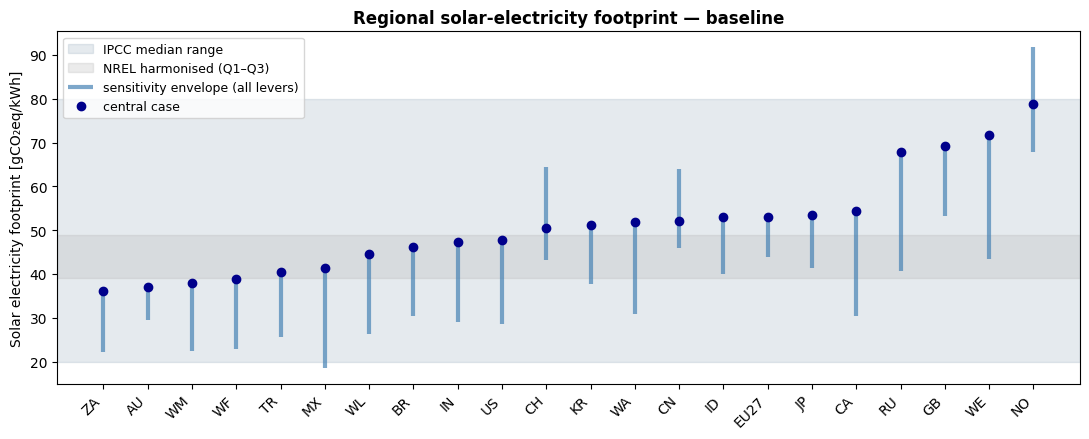

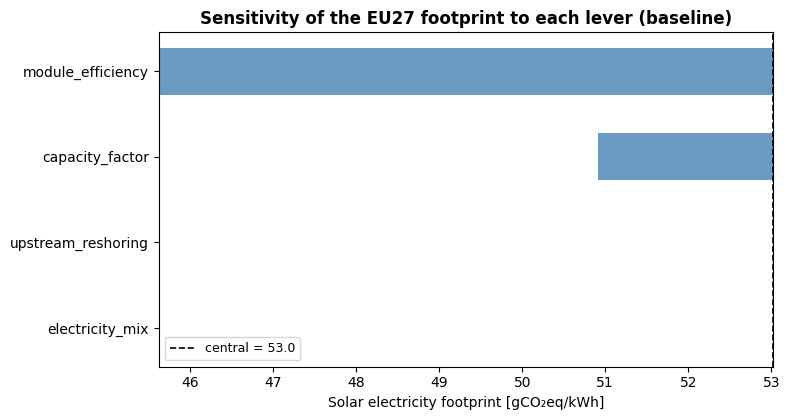

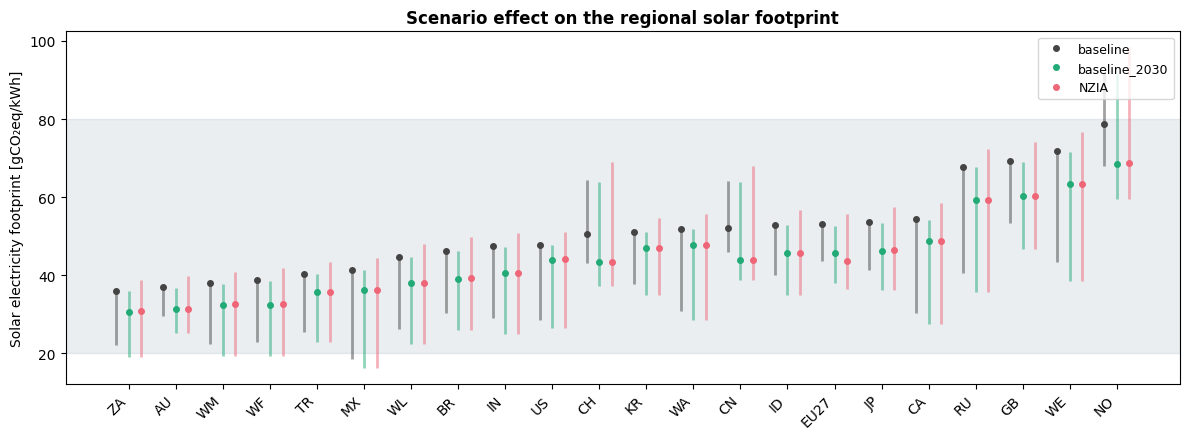

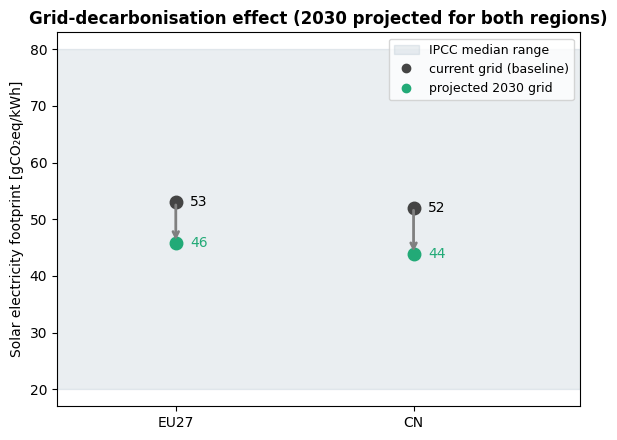

In [5]:
paths = figures.make_all(sens_dir, cfg["outputs"]["dir"] / "figures")
for p in paths:
    print(p)

In [ ]:
from IPython.display import Image
Image(str(paths[0]))

## 7. Save the extended database (optional)

Export one scenario of the augmented hybrid database (flows + coefficients) as parquet, for
sharing or re-use. It can be read back with `mario.parse_from_parquet`.

In [ ]:
db.to_parquet(
    path=str(cfg["outputs"]["dir"] / "extended_db"),
    flows=True, coefficients=True, scenario="baseline",
)
print("saved to", cfg["outputs"]["dir"] / "extended_db")